# Proyecto 2 — Heap con imágenes

Página de referencia: <https://www.cs.usfca.edu/~galles/visualization/Heap.html>

En el capítulo 9 construyeron una clase `Heap` (min heap) cuyo arreglo queda **igual** al de la página después de cada operación. En este proyecto, a ese heap se le agrega la posibilidad de **tomar una imagen** de cómo queda constituido después de cada operación.

## 1. El heap

Use **su propia** clase `Heap` del cuaderno `ch09_construyendo_un_heap.ipynb`, con las mismas convenciones de la página:

- `self.arreglo[0]` es `-INF` (`float('-inf')`) y no hace parte del heap.
- La raíz está en `self.arreglo[1]`.
- Los hijos de la posición `i` están en `2*i` y `2*i + 1`.

Solo debe tener las tres operaciones de la página:

| Botón de la página | Método |
|---|---|
| **Insert** | `insert(valor)` |
| **Remove Smallest** | `remove_smallest()` |
| **BuildHeap** | `build_heap(lista)` |

Después de cada operación, `self.arreglo` debe quedar **igual** al arreglo de la página.

## 2. `build_heap(lista)`

Recibe una lista y deja `self.arreglo` convertido en un heap **igual** al que produce el botón **BuildHeap** de la página.

El botón BuildHeap de la página usa la lista `[31, 30, 29, ..., 1]`; con esa lista puede comparar su resultado.

## 3. La imagen

Cada una de las tres operaciones recibe un parámetro opcional `imagen`:

```python
H.insert(5, imagen=True)
H.remove_smallest(imagen=True)
H.build_heap([31, 30, 29, 28], imagen=True)
```

- Si `imagen=False` (valor por defecto), la operación no muestra nada.
- Si `imagen=True`, al terminar la operación se muestra una imagen del **árbol** del heap.

La imagen muestra **solo el estado final** del heap después de la operación (no los pasos intermedios ni una animación):

- cada nodo con su valor;
- las aristas entre cada nodo y sus hijos;
- la raíz arriba y cada nivel debajo del anterior, con los hijos izquierdos a la izquierda y los derechos a la derecha, como el árbol de la página.

El `-INF` de la posición 0 no aparece en la imagen.

## 4. Ejemplo

```python
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)    # imagen del heap con 4, 10 y 7
H.remove_smallest(imagen=True)
```

La primera imagen debe mostrar `4` en la raíz con hijos `10` y `7`, como la página después de insertar 10, 4 y 7.

## 5. Su solución en `heap.py`

La clase `Heap` debe quedar en un archivo **`heap.py`** (con ese nombre exacto) en su repositorio, en

```
student_work/Proyecto2/heap.py
```

para luego **importarla**:

```python
from heap import Heap
```

Escriba su clase en la celda de abajo. La primera línea, `%%writefile heap.py`, **no** ejecuta el código: guarda el contenido de la celda en el archivo `heap.py`, en la misma carpeta de este cuaderno. Cada vez que modifique su clase, vuelva a ejecutar esa celda para sobrescribir el archivo.

- El archivo debe poder importarse sin errores: no deje pruebas sueltas en él. Si quiere dejar pruebas dentro del `.py`, póngalas debajo de `if __name__ == "__main__":`.
- `from heap import Heap` no toma sus cambios hasta que reinicie el kernel; para releer el archivo sin reiniciar use `importlib.reload` como en la celda de prueba.
- No olvide hacer *commit* y *push* de `heap.py` a su repositorio.

In [1]:
%%writefile heap.py
class Heap:

    def __init__(self):
        self.arreglo = [float('-inf')]

Writing heap.py


In [5]:
import matplotlib.pyplot as plt
import math

In [2]:
import matplotlib.pyplot as plt

class Heap:

    def __init__(self):
        self.arreglo = [float('-inf')]

    def insert(self, valor, imagen = False):
        self.arreglo.append(valor)
        indice_hijo = len(self.arreglo) -1
        hijo = self.arreglo[indice_hijo]
        indice_padre = indice_hijo // 2
        padre = self.arreglo[indice_padre]

        while hijo < padre:
            self.arreglo[indice_hijo], self.arreglo[indice_padre] = self.arreglo[indice_padre], self.arreglo[indice_hijo]
            indice_hijo = indice_padre
            indice_padre = indice_hijo // 2
            hijo = self.arreglo[indice_hijo]
            padre = self.arreglo[indice_padre]

        if imagen:
            self._dibujar_heap()

    def remove_smallest(self,imagen = False):
        if len(self.arreglo) == 1:
            return None
        min = self.arreglo[1]
        ultimo = self.arreglo[-1]
        self.arreglo[-1] = min
        self.arreglo[1] = ultimo
        self.arreglo.pop()
        i = 1
        while i * 2 < len(self.arreglo):

            izquierdo = i * 2
            derecho = i * 2 + 1

            if derecho < len(self.arreglo):

                if self.arreglo[izquierdo] <= self.arreglo[derecho]:

                    if self.arreglo[i] > self.arreglo[izquierdo]:
                        self.arreglo[i], self.arreglo[izquierdo] = self.arreglo[izquierdo], self.arreglo[i]
                        i = izquierdo
                    else:
                        break

                else:

                    if self.arreglo[i] > self.arreglo[derecho]:
                        self.arreglo[i], self.arreglo[derecho] = self.arreglo[derecho], self.arreglo[i]
                        i = derecho
                    else:
                        break

            else:
                if self.arreglo[i] > self.arreglo[izquierdo]:
                    self.arreglo[i], self.arreglo[izquierdo] = self.arreglo[izquierdo], self.arreglo[i]
                    i = izquierdo
                else:
                    break
        if imagen:
            self._dibujar_heap()


        return min


    def build_heap(self, lista, imagen = False):
        heap = [float('-inf')]
        for i in lista:
            heap.append(i)

        numro_elementos = len(heap) - 1
        ultimo_padre = numro_elementos // 2

        for i in range(ultimo_padre, 0, -1):
            while i * 2 < len(heap):
                izquierdo = i * 2
                derecho = i * 2 + 1

                menor = izquierdo

                if derecho < len(heap) and heap[derecho] < heap[izquierdo]:
                    menor = derecho

                if heap[i] > heap[menor]:
                    heap[i], heap[menor] = heap[menor], heap[i]
                    i = menor
                else:
                    break

        self.arreglo = heap

        if imagen:
            self._dibujar_heap()

    def _dibujar_heap(self):
        if len(self.arreglo) <= 1:
            print("El heap está vacío")
            return

        n = len(self.arreglo) - 1
        niveles = n.bit_length()
        fig, ax = plt.subplots(figsize=(max(6, 2 ** (niveles - 1) * 0.7), niveles * 1.3))

        posiciones = {}
        for i in range(1, n + 1):
            nivel = i.bit_length() - 1
            posicion = i - 2 ** nivel
            posiciones[i] = ((posicion + 0.5) / 2 ** nivel, -nivel)

        for i in range(2, n + 1):
            x1, y1 = posiciones[i // 2]
            x2, y2 = posiciones[i]
            ax.plot([x1, x2], [y1, y2], color="black", zorder=1)

        for i in range(1, n + 1):
            x, y = posiciones[i]
            ax.text(x, y, str(self.arreglo[i]), ha="center", va="center", zorder=2,
                        bbox=dict(boxstyle="circle,pad=0.4", fc="skyblue", ec="black"))

        ax.set_xlim(0, 1)
        ax.set_ylim(-niveles + 0.5, 0.5)
        ax.axis("off")
        plt.show()

1. insert OK: [-inf, 4, 10, 7]
2. remove_smallest OK: [-inf, 7, 10]
3. heap vacío OK
4. build_heap pequeño OK: [-inf, 1, 2, 3, 5, 4]
5. build_heap 31..1 válido: [1, 9, 2, 13, 10, 5, 3, 15, 14, 11, 21, 7, 6, 4, 17, 16, 24, 28, 23, 12, 22, 27, 30, 8, 20, 26, 19, 31, 18, 25, 29]
6. remove_smallest repetido OK (sale ordenado)
7. pruebas aleatorias (con duplicados) OK
8a. tras insertar 5,5,5,3: [-inf, 3, 5, 5, 5]
8b. tras remove_smallest: [-inf, 5, 5, 5]

9. Imágenes:


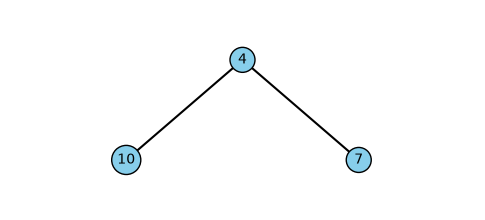

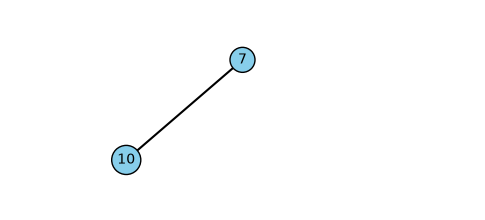

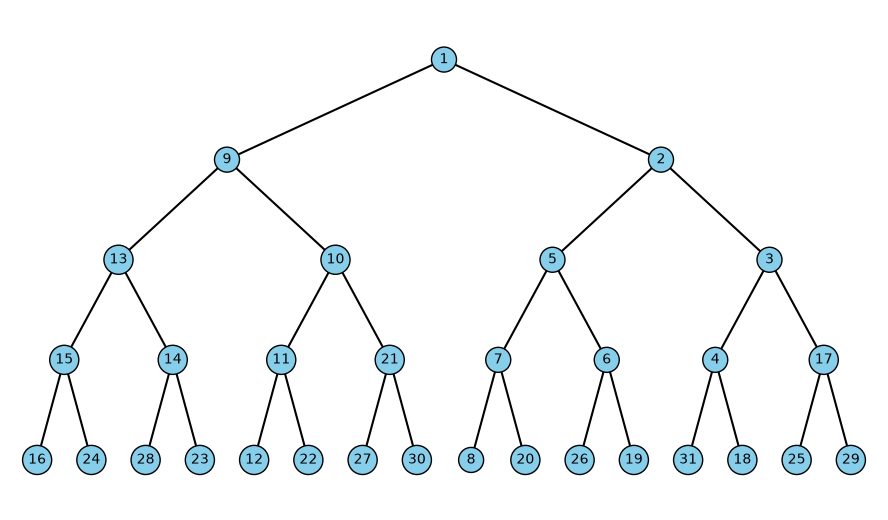

El heap está vacío


In [4]:
import importlib
import heap
importlib.reload(heap)
from heap import Heap

INF = float('-inf')

def es_heap_valido(arr):
    """Cada padre debe ser <= que sus hijos."""
    for i in range(2, len(arr)):
        if arr[i // 2] > arr[i]:
            return False
    return arr[0] == INF

# 1. Ejemplo del enunciado
H = Heap()
H.insert(10)
H.insert(4)
H.insert(7)
assert H.arreglo == [INF, 4, 10, 7], H.arreglo
print("1. insert OK:", H.arreglo)

# 2. remove_smallest devuelve el mínimo y reacomoda
m = H.remove_smallest()
assert m == 4 and H.arreglo == [INF, 7, 10], (m, H.arreglo)
print("2. remove_smallest OK:", H.arreglo)

# 3. Heap vacío
V = Heap()
assert V.remove_smallest() is None
assert V.arreglo == [INF]
print("3. heap vacío OK")

# 4. build_heap con un caso pequeño (calculado a mano)
B = Heap()
B.build_heap([5, 4, 3, 2, 1])
assert B.arreglo == [INF, 1, 2, 3, 5, 4], B.arreglo
print("4. build_heap pequeño OK:", B.arreglo)

# 5. build_heap con la lista de la página (31..1)
G = Heap()
G.build_heap(list(range(31, 0, -1)))
assert es_heap_valido(G.arreglo) and len(G.arreglo) == 32
print("5. build_heap 31..1 válido:", G.arreglo[1:])

# 6. Extraer todo debe dar la lista ordenada
orden = [G.remove_smallest() for _ in range(31)]
assert orden == list(range(1, 32)), orden
assert G.arreglo == [INF]
print("6. remove_smallest repetido OK (sale ordenado)")

# 7. Prueba aleatoria: insert y remove_smallest contra sorted
import random
for _ in range(200):
    datos = [random.randint(1, 20) for _ in range(random.randint(0, 40))]
    R = Heap()
    for d in datos:
        R.insert(d)
        assert es_heap_valido(R.arreglo)
    salida = []
    while len(R.arreglo) > 1:
        salida.append(R.remove_smallest())
        assert es_heap_valido(R.arreglo)
    assert salida == sorted(datos)

    R2 = Heap()
    R2.build_heap(datos)
    assert es_heap_valido(R2.arreglo)
print("7. pruebas aleatorias (con duplicados) OK")

# 8. Duplicados: compara estos arreglos con la página
D = Heap()
for v in [5, 5, 5, 3]:
    D.insert(v)
print("8a. tras insertar 5,5,5,3:", D.arreglo)
D.remove_smallest()
print("8b. tras remove_smallest:", D.arreglo)

# 9. Imágenes (revisa visualmente)
print("\n9. Imágenes:")
I = Heap()
I.insert(10)
I.insert(4)
I.insert(7, imagen=True)          # raíz 4, hijos 10 y 7
I.remove_smallest(imagen=True)    # raíz 7, hijo 10
I.build_heap(list(range(31, 0, -1)), imagen=True)   # 31 nodos, sin solaparse
Heap().build_heap([], imagen=True)                  # heap vacío

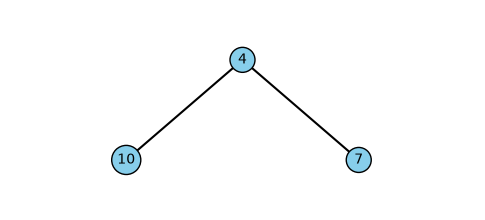

In [1]:
import importlib
import heap
importlib.reload(heap)          # vuelve a leer heap.py si lo cambió
from heap import Heap

H = Heap()
H.insert(10)
H.insert(4)
H.insert(7, imagen=True)

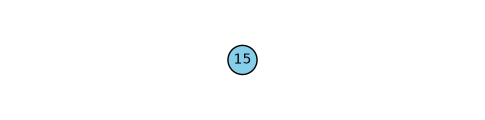

1 [-inf, 15]


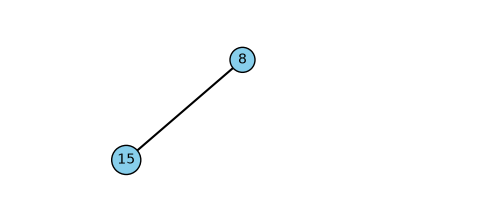

2 [-inf, 8, 15]


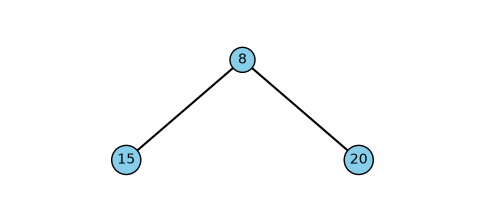

3 [-inf, 8, 15, 20]


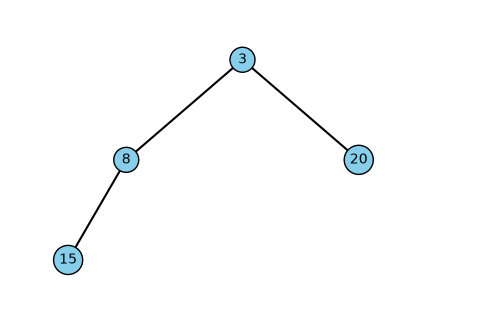

4 [-inf, 3, 8, 20, 15]


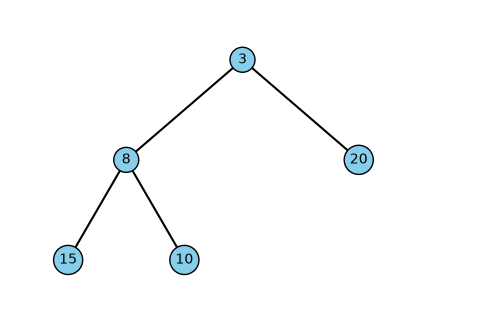

5 [-inf, 3, 8, 20, 15, 10]


In [2]:
import os
import importlib
import heap
importlib.reload(heap)
from heap import Heap

os.makedirs("fotos", exist_ok=True)     # crea la carpeta fotos si no existe

valores = [15, 8, 20, 3, 10]            # NO cambie esta lista

H = Heap()
for i, v in enumerate(valores, start=1):
    H.insert(v, imagen=True)
    # guarde aquí la imagen de esta inserción en f"fotos/insert_{i}.png"
    print(i, H.arreglo)